### Import Python Libraries

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
print("First cell output")

First cell output


### Load the Dataset

In [3]:
# Loading the Dataset

df = pd.read_csv("../dataset/bank.csv")
print("Dataset loaded successfully!")
print("Shape:", df.shape)


Dataset loaded successfully!
Shape: (11162, 17)


### Explore the Dataset and understand the dataset characterstics

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [7]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='str')

In [8]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


In [10]:
df['deposit'].value_counts()

deposit
no     5873
yes    5289
Name: count, dtype: int64

In [11]:
df.isnull().sum().sum()

np.int64(0)

##### The Dataset is of a Bank Marketting that contains 11,162 rows and 17 columns. The target variable will be deposit which will tell that the customer has created a deposit with the bank , yes or no . There are no missing values as such.

### Data Pre Processing

In [12]:
# First we will have to separate the featurs and the target.

X = df.drop('deposit',axis =1)
y = df['deposit']

print("Features shape:",X.shape)
print("Target shape:", y.shape)


Features shape: (11162, 16)
Target shape: (11162,)


In [13]:
# Lets do some encoding on the target variable.
y = y.map({'no':0 ,'yes':1})
y.head()

0    1
1    1
2    1
3    1
4    1
Name: deposit, dtype: int64

In [14]:
#Finally lets divide the data on training and test data

from sklearn.model_selection import train_test_split

X_train , X_test,y_train,y_test = train_test_split(X,y,test_size = 0.20,random_state =42,stratify=y)

print("Training Set:",X_train.shape)
print("Testing Set:",X_test.shape)

Training Set: (8929, 16)
Testing Set: (2233, 16)


In [15]:
#Idenfitying the Numerical and Categorical Columns

categorical_cols = X.select_dtypes(include = 'object').columns
numerical_cols = X.select_dtypes(exclude = 'object').columns

print("Categorical Columns:")
print(list(categorical_cols))

print("\nNumerical Columns:")
print(list(numerical_cols))

Categorical Columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical Columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


C:\Users\tiwar\AppData\Local\Temp\ipykernel_35496\1901844671.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include = 'object').columns
C:\Users\tiwar\AppData\Local\Temp\ipykernel_35496\1901844671.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are excluded by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `exclude` to remove them, or to `include` to keep them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_gu

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(),numerical_cols),
        ('cat',OneHotEncoder(handle_unknown='ignore'),categorical_cols)
    ]
)

### Creating the Pre Processor

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


## Training the Dataset on various Models

#### Logistic Regression

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ('preprocessor',preprocessor),
    ('classifier', LogisticRegression (max_iter = 1000))
])

lr_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:,1]

print("Accuracy :" , round(accuracy_score(y_test, y_pred_lr),4))
print("Precision :" ,round(precision_score(y_test,y_pred_lr),4))
print("Recall : " ,round(recall_score(y_test,y_pred_lr),4))
print("F1 Score :", round(f1_score(y_test, y_pred_lr), 4))
print("MCC      :", round(matthews_corrcoef(y_test, y_pred_lr), 4))
print("AUC      :", round(roc_auc_score(y_test, y_prob_lr), 4))

Accuracy : 0.8262
Precision : 0.8278
Recall :  0.7996
F1 Score : 0.8135
MCC      : 0.6513
AUC      : 0.9071


### Moving next to the Descision Tree Classifier 

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

tree_classifier = Pipeline([
    ('data_preparation',preprocessor),
    ('model',DecisionTreeClassifier(
        max_depth =6,
        random_state =42
    ))
])

tree_classifier.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('data_preparation', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining 

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

# Store all model results here
model_results = []

def evaluate_model(trained_model, model_name):
    
    predictions = trained_model.predict(X_test)
    probabilities = trained_model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    mcc = matthews_corrcoef(y_test, predictions)
    auc = roc_auc_score(y_test, probabilities)

    print(f"\n{'='*50}")
    print(f"{model_name}")
    print(f"{'='*50}")

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")
    print(f"MCC      : {mcc:.4f}")
    print(f"AUC      : {auc:.4f}")

    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc,
        "AUC": auc
    })

### K- Nearest Neighbours (KNN)

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline([
    
    ('data_preparation', preprocessor),
    
    ('classifier',
     KNeighborsClassifier(
         n_neighbors=7
     ))
])

knn_pipeline.fit(
    X_train,
    y_train
)

print("KNN model trained successfully.")

KNN model trained successfully.


In [23]:
evaluate_model(
    knn_pipeline,
    "K-Nearest Neighbors"
)


K-Nearest Neighbors
Accuracy : 0.8222
Precision: 0.8282
Recall   : 0.7883
F1 Score : 0.8077
MCC      : 0.6433
AUC      : 0.8881


#### In KNN the classifier predicts wether the costumer has created the bank deposit or not by analyzing the neighboring observations. As its a distance-based , feature scaling it ensure the comparison is done frelly among the numerical features.

### Naive Bayes Classifier

In [24]:
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline

naive_bayes_pipeline = Pipeline([
    
    ('data_preparation', preprocessor),
    
    ('classifier', BernoulliNB())
])

naive_bayes_pipeline.fit(
    X_train,
    y_train
)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


In [25]:
evaluate_model(
    naive_bayes_pipeline,
    "Naive Bayes"
)


Naive Bayes
Accuracy : 0.7232
Precision: 0.7170
Recall   : 0.6871
F1 Score : 0.7017
MCC      : 0.4442
AUC      : 0.8007


#### Naive Bayes took relatively less time and it was faster approach. 

### Random Forest 

#### In Random Forest we combine multiple decision trees to improve the performance .

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline([
    
    ('data_preparation', preprocessor),
    
    ('classifier',
     RandomForestClassifier(
         n_estimators=200,
         max_depth=10,
         random_state=42
     ))
])

random_forest_pipeline.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [27]:
evaluate_model(
    random_forest_pipeline,
    "Random Forest"
)


Random Forest
Accuracy : 0.8513
Precision: 0.8190
Recall   : 0.8809
F1 Score : 0.8488
MCC      : 0.7047
AUC      : 0.9173


In [28]:
evaluate_model(
    tree_classifier,
    "Decision Tree"
)


Decision Tree
Accuracy : 0.8110
Precision: 0.8093
Recall   : 0.7864
F1 Score : 0.7977
MCC      : 0.6207
AUC      : 0.8798


### Random Forest as stated above work as combination of the multiple decision trees and generally give higher accuracy .

In [29]:
evaluate_model(
    lr_model,
    "Logistic Regression"
)


Logistic Regression
Accuracy : 0.8262
Precision: 0.8278
Recall   : 0.7996
F1 Score : 0.8135
MCC      : 0.6513
AUC      : 0.9071


In [30]:
model_results

[{'Model': 'K-Nearest Neighbors',
  'Accuracy': 0.8222122704881325,
  'Precision': 0.8282025819265144,
  'Recall': 0.7882797731568998,
  'F1 Score': 0.8077481840193704,
  'MCC': 0.643266313477415,
  'AUC': 0.8881132606684631},
 {'Model': 'Naive Bayes',
  'Accuracy': 0.7232422749664129,
  'Precision': 0.7169625246548323,
  'Recall': 0.6871455576559546,
  'F1 Score': 0.7017374517374517,
  'MCC': 0.44415754626347187,
  'AUC': 0.8006921932188391},
 {'Model': 'Random Forest',
  'Accuracy': 0.851321092700403,
  'Precision': 0.8189806678383128,
  'Recall': 0.8809073724007561,
  'F1 Score': 0.848816029143898,
  'MCC': 0.7047497008250069,
  'AUC': 0.9173406266339542},
 {'Model': 'Decision Tree',
  'Accuracy': 0.8110165696372593,
  'Precision': 0.8093385214007782,
  'Recall': 0.7863894139886578,
  'F1 Score': 0.7976989453499521,
  'MCC': 0.6206827989308031,
  'AUC': 0.8797639062060089},
 {'Model': 'Logistic Regression',
  'Accuracy': 0.8262427227944469,
  'Precision': 0.8277886497064579,
  'Reca

In [31]:
comparison_df = pd.DataFrame(model_results)

comparison_df = comparison_df.drop_duplicates(
    subset='Model',
    keep='last'
)

comparison_df = comparison_df.round(4)

comparison_df = comparison_df.sort_values(
    by='Accuracy',
    ascending=False
)

comparison_df.reset_index(
    drop=True,
    inplace=True
)

comparison_df

C:\Users\tiwar\AppData\Local\Temp\ipykernel_35496\517112843.py:15: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  comparison_df.reset_index(


,Model,Accuracy,Precision,Recall,F1 Score,MCC,AUC
0,Random Forest,0.8513,0.8190,0.8809,0.8488,0.7047,0.9173
1,Logistic Regression,0.8262,0.8278,0.7996,0.8135,0.6513,0.9071
2,K-Nearest Neighbors,0.8222,0.8282,0.7883,0.8077,0.6433,0.8881
3,Decision Tree,0.8110,0.8093,0.7864,0.7977,0.6207,0.8798
4,Naive Bayes,0.7232,0.7170,0.6871,0.7017,0.4442,0.8007


In [32]:
comparison_df.to_csv(
    "../model/model_comparison.csv",
    index=False
)


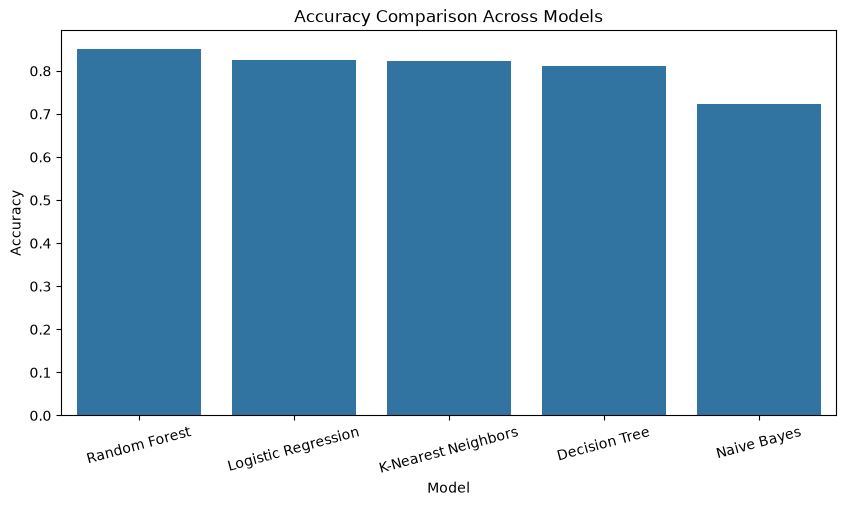

In [33]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison Across Models')
plt.xticks(rotation=15)

plt.show()

In [34]:
import joblib

joblib.dump(lr_model, "../model/logistic_regression.pkl")
joblib.dump(tree_classifier, "../model/decision_tree.pkl")
joblib.dump(knn_pipeline, "../model/knn.pkl")
joblib.dump(naive_bayes_pipeline, "../model/naive_bayes.pkl")
joblib.dump(random_forest_pipeline, "../model/random_forest.pkl")

print("All models are now saved successfully!")

All models are now saved successfully!
